In [1]:
!pip install transformers datasets accelerate scikit-learn

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer

print("Supriya K 24BAD118")
print("Libraries Imported Successfully")

Supriya K 24BAD118
Libraries Imported Successfully


In [3]:
dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

print("\nSample Review:")
print(dataset["train"][0])

print("\nTraining Samples:", len(dataset["train"]))
print("Testing Samples:", len(dataset["test"]))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Sample Review:
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking

Negative Reviews: 12500
Positive Reviews: 12500


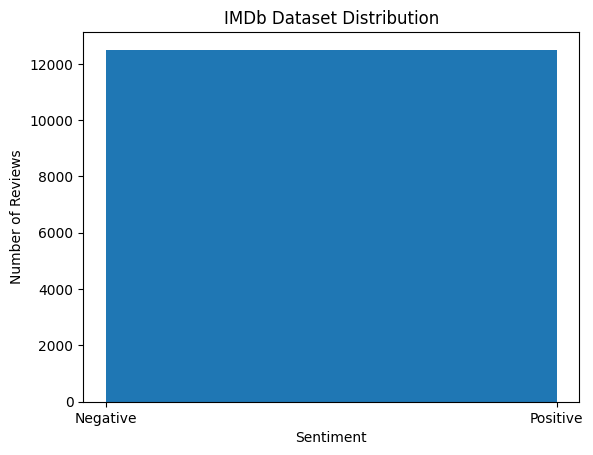

In [4]:
labels = dataset["train"]["label"]

print("Negative Reviews:", labels.count(0))
print("Positive Reviews:", labels.count(1))

plt.hist(labels, bins=2)
plt.xticks([0, 1], ["Negative", "Positive"])
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.title("IMDb Dataset Distribution")
plt.show()

In [5]:
train_data = dataset["train"].shuffle(
    seed=42
).select(range(2000))

test_data = dataset["test"].shuffle(
    seed=42
).select(range(500))

print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))

Training Samples: 2000
Testing Samples: 500


In [6]:
model_name = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT Tokenizer Loaded Successfully")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT Tokenizer Loaded Successfully


In [7]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_data = train_data.map(
    tokenize_function,
    batched=True
)

test_data = test_data.map(
    tokenize_function,
    batched=True
)

print("Tokenization Completed Successfully")

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenization Completed Successfully


In [8]:
train_data = train_data.rename_column(
    "label", "labels"
)

test_data = test_data.rename_column(
    "label", "labels"
)

train_data.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_data.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print("Training and Testing Data Prepared Successfully")

Training and Testing Data Prepared Successfully


PART B

In [9]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("DistilBERT Model Loaded Successfully")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT Model Loaded Successfully


In [10]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

def compute_metrics(pred):
    predictions = np.argmax(pred.predictions, axis=1)
    labels = pred.label_ids

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions),
        "recall": recall_score(labels, predictions),
        "f1": f1_score(labels, predictions)
    }

In [11]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./imdb_results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=1,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

print("Training Parameters Configured")

Training Parameters Configured


In [12]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=test_data,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()

print("Model Training Completed Successfully")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.409474,0.820000,0.788889,0.865854,0.825581


Model Training Completed Successfully


In [13]:
results = trainer.evaluate()

print("Evaluation Results")

print("Accuracy:", results["eval_accuracy"])
print("Precision:", results["eval_precision"])
print("Recall:", results["eval_recall"])
print("F1 Score:", results["eval_f1"])

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.409474,1,0.820000,0.788889,0.865854,0.825581


Evaluation Results
Accuracy: 0.82
Precision: 0.7888888888888889
Recall: 0.8658536585365854
F1 Score: 0.8255813953488372


In [14]:
reviews = [
    "This movie was excellent and very entertaining.",
    "The movie was boring and disappointing.",
    "I really enjoyed this wonderful film.",
    "The acting was terrible and the story was poor."
]

device = next(model.parameters()).device

for review in reviews:

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()

    label = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", label)
    print()

Review: This movie was excellent and very entertaining.
Predicted Sentiment: Positive

Review: The movie was boring and disappointing.
Predicted Sentiment: Negative

Review: I really enjoyed this wonderful film.
Predicted Sentiment: Positive

Review: The acting was terrible and the story was poor.
Predicted Sentiment: Negative



In [15]:
model.save_pretrained("./imdb_distilbert_model")
tokenizer.save_pretrained("./imdb_distilbert_model")

print("Model and Tokenizer Saved Successfully")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and Tokenizer Saved Successfully


PART C

In [16]:
from transformers import AutoTokenizer
from transformers import AutoModelForSeq2SeqLM

t5_tokenizer = AutoTokenizer.from_pretrained(
    "google-t5/t5-small"
)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    "google-t5/t5-small"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

t5_model.to(device)

print("T5 Model Loaded Successfully")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5 Model Loaded Successfully


In [19]:
text = """
Artificial Intelligence is a technology that enables
machines to perform tasks that normally require human intelligence.
It is used in healthcare, education and transportation.
"""

input_text = "summarize: " + text

print("Input Text:")
print(text)

inputs = t5_tokenizer(
    input_text,
    return_tensors="pt",
    max_length=256,
    truncation=True
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

print("Input Tokenization Completed")



Input Text:

Artificial Intelligence is a technology that enables
machines to perform tasks that normally require human intelligence.
It is used in healthcare, education and transportation.

Input Tokenization Completed


In [21]:
outputs = t5_model.generate(
    inputs["input_ids"],
    max_length=60,
    num_beams=2
)

generated_text = t5_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Generated Summary:")
print(generated_text)



Generated Summary:
online education allows students to learn from anywhere.


In [22]:
texts = [
    "summarize: Online education allows students to learn from anywhere.",
    "summarize: Trees provide oxygen and protect the environment.",
    "summarize: Exercise improves physical and mental health."
]

generated_outputs = []

for text in texts:

    inputs = t5_tokenizer(
        text,
        return_tensors="pt",
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=50,
        num_beams=2
    )

    result = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    generated_outputs.append(result)

    print("\nInput:", text)
    print("Generated Output:", result)


Input: summarize: Online education allows students to learn from anywhere.
Generated Output: online education allows students to learn from anywhere.

Input: summarize: Trees provide oxygen and protect the environment.
Generated Output: trees provide oxygen and protect the environment.

Input: summarize: Exercise improves physical and mental health.
Generated Output: exercise improves physical and mental health.


In [23]:
df = pd.DataFrame({
    "Input": texts,
    "Generated Output": generated_outputs
})

df.to_csv("generated_outputs.csv", index=False)

print(df)

print("Generated Outputs Saved Successfully")

                                               Input  \
0  summarize: Online education allows students to...   
1  summarize: Trees provide oxygen and protect th...   
2  summarize: Exercise improves physical and ment...   

                                    Generated Output  
0  online education allows students to learn from...  
1  trees provide oxygen and protect the environment.  
2      exercise improves physical and mental health.  
Generated Outputs Saved Successfully


PART D


In [24]:
test_reviews = [
    "The movie was fantastic and enjoyable.",
    "The movie was terrible and boring.",
    "I loved the performances in this film.",
    "I disliked the movie because it was disappointing."
]

for review in test_reviews:

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Class:", sentiment)
    print()

Review: The movie was fantastic and enjoyable.
Predicted Class: Positive

Review: The movie was terrible and boring.
Predicted Class: Negative

Review: I loved the performances in this film.
Predicted Class: Positive

Review: I disliked the movie because it was disappointing.
Predicted Class: Negative



In [25]:
results = trainer.evaluate()

print("Classification Performance")

print("Accuracy:", results["eval_accuracy"])
print("Precision:", results["eval_precision"])
print("Recall:", results["eval_recall"])
print("F1 Score:", results["eval_f1"])

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.409474,1,0.820000,0.788889,0.865854,0.825581


Classification Performance
Accuracy: 0.82
Precision: 0.7888888888888889
Recall: 0.8658536585365854
F1 Score: 0.8255813953488372


In [26]:
test_texts = [
    "summarize: Computers help people perform tasks quickly.",
    "summarize: Solar energy is a renewable source of energy.",
    "summarize: Reading books improves knowledge and vocabulary."
]

for text in test_texts:

    inputs = t5_tokenizer(
        text,
        return_tensors="pt",
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=50,
        num_beams=2
    )

    result = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("Input:", text)
    print("Generated Output:", result)
    print()

Input: summarize: Computers help people perform tasks quickly.
Generated Output: computers help people perform tasks quickly.

Input: summarize: Solar energy is a renewable source of energy.
Generated Output: solar energy is a renewable source of energy.

Input: summarize: Reading books improves knowledge and vocabulary.
Generated Output: reading books improves knowledge and vocabulary.



In [27]:
text = "summarize: Artificial Intelligence is transforming modern industries."

inputs = t5_tokenizer(
    text,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

for length in [20, 40, 60]:

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=length,
        num_beams=2
    )

    result = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("Maximum Length:", length)
    print("Generated Output:", result)
    print()

Maximum Length: 20
Generated Output: Artificial Intelligence is transforming modern industries.

Maximum Length: 40
Generated Output: Artificial Intelligence is transforming modern industries.

Maximum Length: 60
Generated Output: Artificial Intelligence is transforming modern industries.



In [29]:
final_results = pd.DataFrame({

    "Accuracy": [results["eval_accuracy"]],
    "Precision": [results["eval_precision"]],
    "Recall": [results["eval_recall"]],
    "F1 Score": [results["eval_f1"]]
})

final_results.to_csv(
    "final_evaluation_results.csv",
    index=False
)

print(final_results)

print("Final Results Saved Successfully")

   Accuracy  Precision    Recall  F1 Score
0      0.82   0.788889  0.865854  0.825581
Final Results Saved Successfully
